# Libraries

In [1]:
import pandas as pd
import numpy as np

#Data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Dataset

In [2]:
df = pd.read_csv("raw_data/cookie_cats.csv")

# Data Understanding

Preliminary questions:
* if an user has retention = True, can he/she have played no games?
    * yes, so retention = login in the app, not necessarily playing
    * this was verified but retention 1 and 7, so 1 week of not playing
    * I don't know the app, but if you login but don't play, then what are you doing in the app?
* retention 7 = True implies that also retention 1 = True?
    * no, so retention 7 does not mean that the user has been logging in for 7 days straight, but has made a login on the $7^{th}$ day

In [12]:
print("Users with retention 1 = True but no games:")
print(df.loc[(df["retention_1"] == True) &
    (df["sum_gamerounds"] == 0)
]["userid"].count())
print("Users with retention 7 = True but no games:")
print(df.loc[(df["retention_7"] == True) &
    (df["sum_gamerounds"] == 0)
]["userid"].count())
print("Users with retention 7 = True but retention 1 = False:")
print(df.loc[(df["retention_7"] == True) &
    (df["retention_1"] == False)
]["userid"].count())

Users with retention 1 = True but no games:
87
Users with retention 7 = True but no games:
29
Users with retention 7 = True but retention 1 = False:
3599


# Analysis

The analysis will focus on inactive users, separated in two categories:
* inactive = did not login (Retention = False)
* passive = did not play (Games = 0)

## Inactive

In [54]:
inactive_df = pd.DataFrame([{
    "users": df["userid"].nunique(),
    "inactive_1": df.loc[df["retention_1"] == False,
                            "userid"].count(),
    "inactive_7": df.loc[df["retention_7"] == False,
                            "userid"].count(),
    "inactive_1_and_7": df.loc[(df["retention_1"] == False) &
                                    (df["retention_7"] == False), 
                                    "userid"].count(),
    "inactive_1_but_active_7": df.loc[(df["retention_1"] == False) &
        (df["retention_7"] == True), 
        "userid"].count(),
    "active_1": df.loc[(df["retention_1"] == True), 
        "userid"].count(),
    "active_1_but_inactive_7": df.loc[(df["retention_1"] == True) &
        (df["retention_7"] == False), 
        "userid"].count(),
    "active_1_and_7": df.loc[(df["retention_1"] == True) &
        (df["retention_7"] == True), 
        "userid"].count()
}])

inactive_df

,users,inactive_1,inactive_7,inactive_1_and_7,inactive_1_but_active_7,active_1,active_1_but_inactive_7,active_1_and_7
0,90189,50036,73408,46437,3599,40153,26971,13182


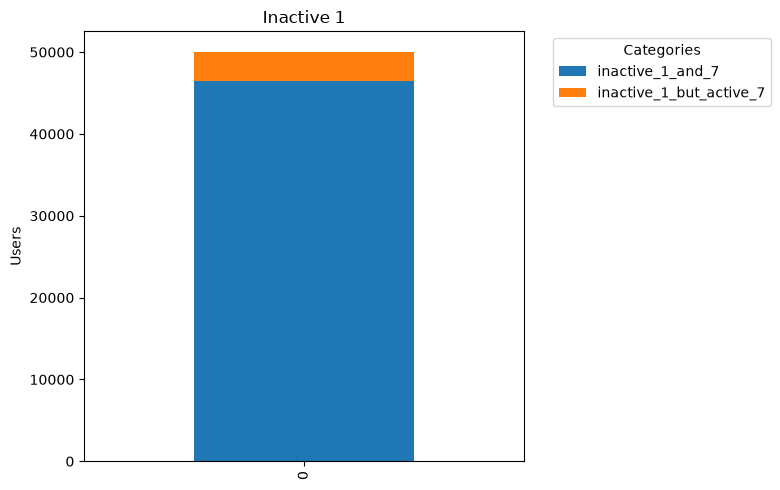

In [47]:
df_plot = inactive_df[["inactive_1_and_7", "inactive_1_but_active_7"]]

ax = df_plot.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    width=0.5
)

ax.set_ylabel("Users")
ax.set_xlabel("")
ax.legend(title="Categories", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("Inactive 1")

plt.tight_layout()
plt.show()

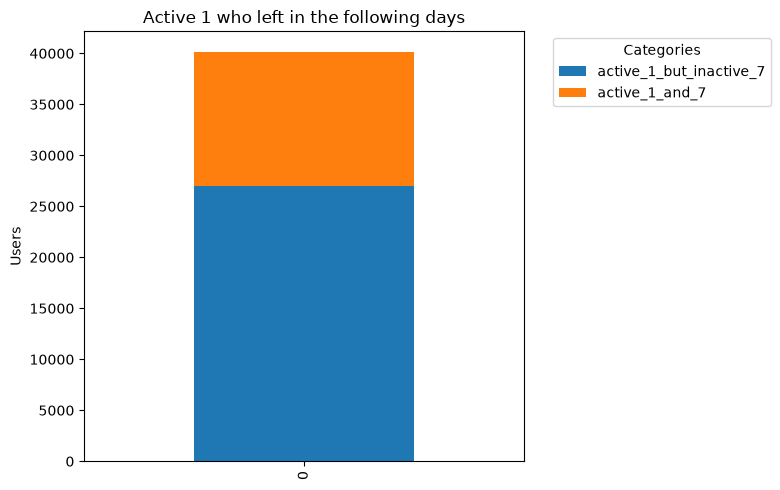

In [56]:
df_plot = inactive_df[["active_1_but_inactive_7", "active_1_and_7"]]

ax = df_plot.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    width=0.5
)

ax.set_ylabel("Users")
ax.set_xlabel("")
ax.legend(title="Categories", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("Active 1 who left in the following days")

plt.tight_layout()
plt.show()

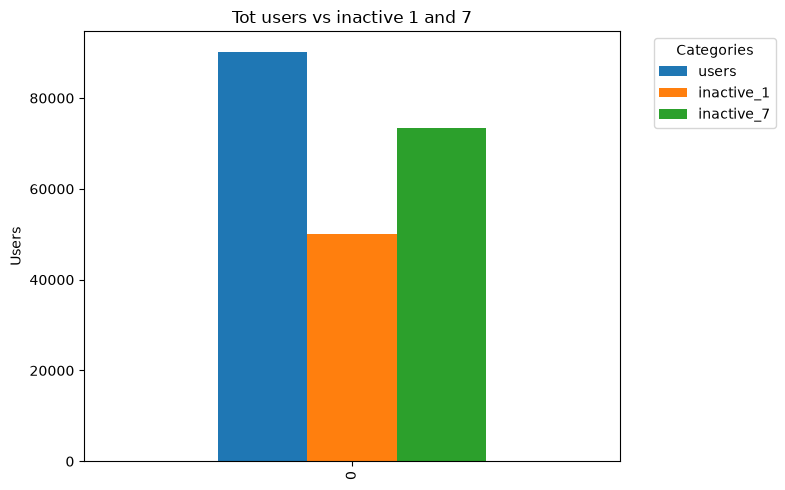

In [50]:
df_plot = inactive_df[["users", "inactive_1", "inactive_7"]]

ax = df_plot.plot(
    kind='bar',
    stacked=False,
    figsize=(8, 5),
    width=0.5
)

ax.set_ylabel("Users")
ax.set_xlabel("")
ax.legend(title="Categories", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("Tot users vs inactive 1 and 7")

plt.tight_layout()
plt.show()

In [52]:
print(round(inactive_df["inactive_7"][0] / inactive_df["users"][0] * 100,
1
), f"% of users are not active the 7th day")

print(round(inactive_df["inactive_1"][0] / inactive_df["users"][0] * 100,
1
), f"% of users are not active the 1st day after installing the app already")

print(round(inactive_df["inactive_1_and_7"][0] / inactive_df["inactive_1"][0] * 100,
1
), f"% of users which were not active the 1st day, are not active even the 7th day")
print("This means that most users are already lost in the first day")

print(round(inactive_df["active_1_but_inactive_7"][0] / (inactive_df["active_1"][0]) * 100,
1
), f"% of users active on the 1st day, left between the 2nd and the 7th day")
print("This means that most users play between 1 and 7 days, but rarely for longer")

81.4 % of users are not active the 7th day
55.5 % of users are not active the 1st day after installing the app already
92.8 % of users which were not active the 1st day, are not active even the 7th day
This means that most users are already lost in the first day
67.2 % of users active on the 1st day, left between the 2nd and the 7th day
This means that most users play between 1 and 7 days, but rarely for longer


## Passive

In [6]:
passive_df = pd.DataFrame([{
    "users": df["userid"].nunique(),
    "passive": df.loc[df["sum_gamerounds"] == 0, 
                                      "userid"].count(),
    "passive_active1": df.loc[(df["retention_1"] == True) &
                                  (df["sum_gamerounds"] == 0), 
                                  "userid"].count(),
    "passive_inactive1": df.loc[(df["retention_1"] == False) &
                                    (df["sum_gamerounds"] == 0), 
                                    "userid"].count(),
    "passive_active7": df.loc[(df["retention_7"] == True) &
                                    (df["sum_gamerounds"] == 0), 
                                    "userid"].count(),
    "passive_inactive7": df.loc[(df["retention_7"] == False) &
                                    (df["sum_gamerounds"] == 0), 
                                    "userid"].count(),
    
}])

passive_df

,users,passive,passive_active1,passive_inactive1,passive_active7,passive_inactive7
0,90189,3994,87,3907,29,3965


In [9]:
print(round(passive_df["passive"][0] / passive_df["users"][0] * 100,
1
), f"% of users are passive in total")

print("Of which", round(passive_df["passive_inactive1"][0] / passive_df["passive"][0] * 100,
1
), f"% are passive and inactive after 1 day")

print("And", round(passive_df["passive_inactive7"][0] / passive_df["passive"][0] * 100,
1
), f"% are passive and inactive after 7 days")

4.4 % of users are passive in total
Of which 97.8 % are passive and inactive after 1 day
And 99.3 % are passive and inactive after 7 days
